In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte
from skimage import data
from skimage.filters import unsharp_mask
from skimage import filters as ski
from skimage import filters, exposure, morphology

In [ ]:
hdul = fits.open('SKA_AA4_r2km_z_7.391__4.33arcmin_3.97arcmin_cube.fits')
cosmo_data = hdul[0].data
cosmo_data = np.squeeze(cosmo_data)
z_index = 51
cosmo_1 = cosmo_data[:, :, z_index]

cosmo_1.shape

(32, 170)

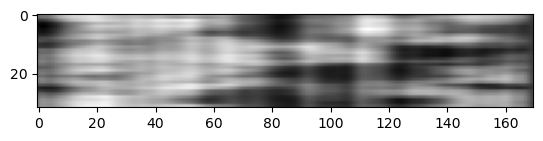

In [ ]:
plt.imshow(cosmo_1, cmap='gray')

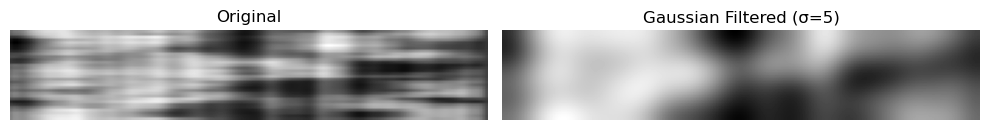

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, img_as_float

# Load a sample image (you can replace this with your own image)
image = cosmo_1  # grayscale image

# Apply Gaussian filter
sigma = 5  # standard deviation, controls amount of blur
smoothed_image = gaussian_filter(image, sigma=sigma)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='grey')
axes[0].set_title("Original")
axes[1].imshow(smoothed_image, cmap='grey')
axes[1].set_title(f"Gaussian Filtered (σ={sigma})")

for ax in axes:
    ax.axis('off')
plt.savefig("Image LT.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()


(array([  2.,   4.,   9.,  32.,  43.,  84.,  93., 100.,  94., 133.,  98.,
        110., 137., 143., 116., 114., 137., 124., 136., 109., 118., 107.,
        133., 156., 140., 124., 132., 159., 155., 180., 165., 163., 185.,
        215., 243., 226., 180., 159., 134., 137., 104.,  87.,  56.,  52.,
         53.,  26.,  20.,   8.,   1.,   4.]),
 array([-8.52575613e-06, -7.75478748e-06, -6.98381837e-06, -6.21284926e-06,
        -5.44188015e-06, -4.67091104e-06, -3.89994239e-06, -3.12897328e-06,
        -2.35800417e-06, -1.58703529e-06, -8.16066290e-07, -4.50973303e-08,
         7.25871644e-07,  1.49684058e-06,  2.26780958e-06,  3.03877869e-06,
         3.80974757e-06,  4.58071645e-06,  5.35168556e-06,  6.12265467e-06,
         6.89362332e-06,  7.66459289e-06,  8.43556154e-06,  9.20653019e-06,
         9.97749976e-06,  1.07484684e-05,  1.15194371e-05,  1.22904066e-05,
         1.30613753e-05,  1.38323439e-05,  1.46033135e-05,  1.53742822e-05,
         1.61452517e-05,  1.69162195e-05,  1.76871

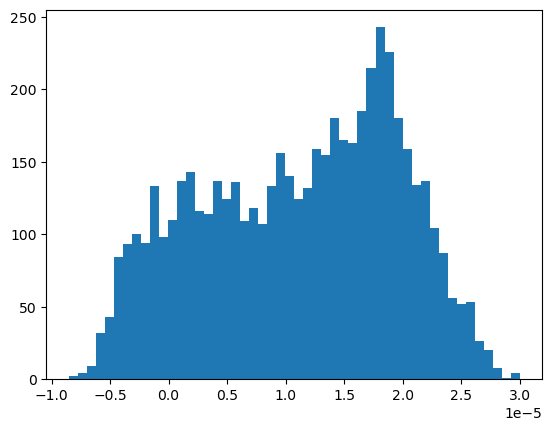

In [ ]:
plt.hist(cosmo_1.flatten(), bins=50)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import exposure

def enhance_visual(image):
    # Smooth image to reduce noise
    smoothed = gaussian_filter(image, sigma=1.2)

    # Apply log stretch to enhance bubble structures
    image_log = np.log1p(smoothed - smoothed.min())

    # Optional: Normalize to [0, 1]
    norm = (image_log - np.min(image_log)) / (np.max(image_log) - np.min(image_log))

    # Histogram Equalization
    hist_eq = exposure.equalize_hist(norm)

    return hist_eq


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import exposure
from skimage.filters.rank import entropy
from skimage.morphology import disk, binary_opening, binary_closing, remove_small_objects
from skimage.filters import threshold_yen
from skimage.util import img_as_ubyte


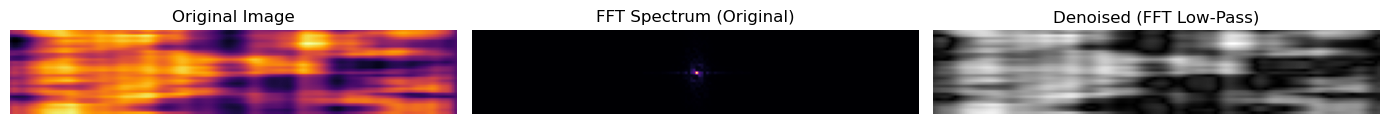

In [ ]:

#FFT FOR THE RAW IMAGE
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift

def fft_low_pass_filter(image, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(image)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(image)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))


    return denoised, f_shift, f_filtered

# Example usage
# image = your 2D image slice (e.g., from FITS or numpy array)
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(image, radius=20)

# Display Results
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='inferno')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fft_original)), cmap='magma')
plt.title("FFT Spectrum (Original)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(denoised_img, cmap='grey')
plt.title("Denoised (FFT Low-Pass)")
plt.axis('off')

plt.tight_layout()
plt.show()


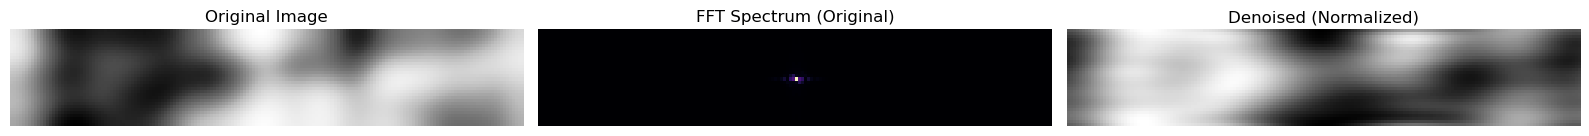

In [ ]:
#FFT FOR ENTROPY

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage.util import invert
from skimage.exposure import rescale_intensity

def fft_low_pass_filter(entropy_map3, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(smoothed_image)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(smoothed_image)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))

    return denoised, f_shift, f_filtered

# ---- Step 1: Apply FFT Filter ----
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(smoothed_image, radius=5)

# ---- Step 2: Normalize and Invert ----
denoised_img_norm = rescale_intensity(denoised_img, in_range='image', out_range=(0, 1))
inverted_img = invert(denoised_img_norm)

# ---- Step 3: Plot All Results ----
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(smoothed_image, cmap='Greys')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fft_original)), cmap='magma')
plt.title("FFT Spectrum (Original)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(denoised_img_norm, cmap='gray')
plt.title("Denoised (Normalized)")
plt.axis('off')


plt.axis('off')

plt.tight_layout()
plt.show()


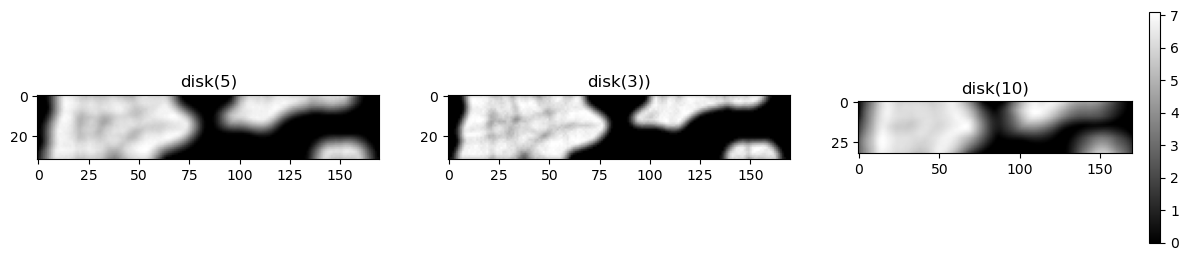

In [ ]:
import numpy as np

from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte

Cosmo_Entropy = img_as_ubyte(exposure.rescale_intensity(smoothed_image))
entropy_map1 = entropy(Cosmo_Entropy, disk(5))
entropy_map2 = entropy(Cosmo_Entropy, disk(3))
entropy_map3 = entropy(Cosmo_Entropy, disk(10))
plt.figure(figsize= (15,3))


plt.subplot(1,3,1); plt.imshow(entropy_map1, cmap='gray')
plt.title("disk(5)")
plt.subplot(1,3,2); plt.imshow(entropy_map2, cmap='gray')
plt.title("disk(3))")
plt.subplot(1,3,3); plt.imshow(entropy_map3,cmap='gray')
plt.title("disk(10)")

plt.colorbar()

plt.show()

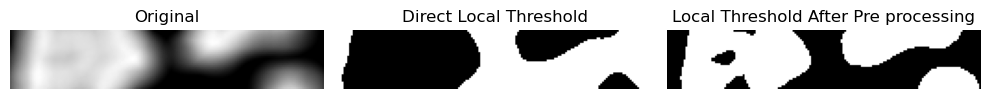

<Figure size 640x480 with 0 Axes>

In [ ]:


from skimage import filters as ski

global_thresh = ski.threshold_otsu(entropy_map3)
binary_global = entropy_map3 < global_thresh

block_size = 101
local_thresh = ski.threshold_local(entropy_map3, block_size, offset=0)
binary_local = entropy_map3 > local_thresh
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10, 5))
ax = axes.ravel()

ax[0].imshow(entropy_map3, cmap='grey')  # use cmap here
ax[0].set_title('Original')

ax[1].imshow(binary_global, cmap='grey')
ax[1].set_title('Direct Local Threshold')

ax[2].imshow(binary_local, cmap='grey')
ax[2].set_title('Local Threshold After Pre processing')

for a in ax:
    a.set_axis_off()

plt.tight_layout()
plt.show()

for a in ax:
    a.set_axis_off()
plt.tight_layout()
plt.show()

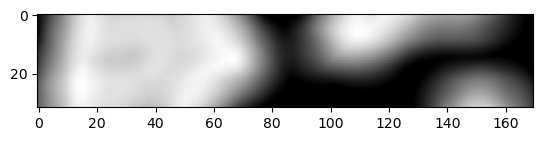

In [ ]:
plt.imshow(entropy_map3, cmap='gray')
plt.show()

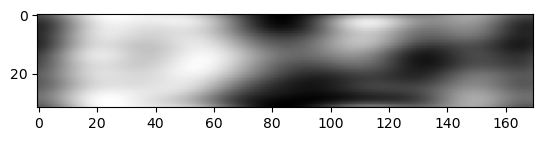

In [ ]:
from skimage import exposure

equalized = exposure.equalize_hist(denoised_img_norm)
plt.imshow(denoised_img_norm, cmap='gray')
plt.show()

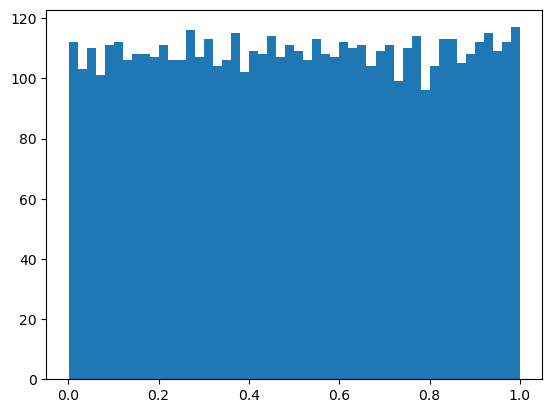

In [ ]:
plt.hist(equalized.flatten(), bins=50)
plt.show()

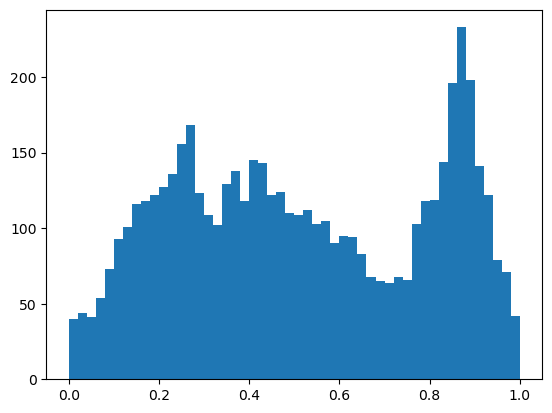

In [ ]:
denoised = plt.hist(denoised_img_norm.flatten(), bins=50)
plt.show()

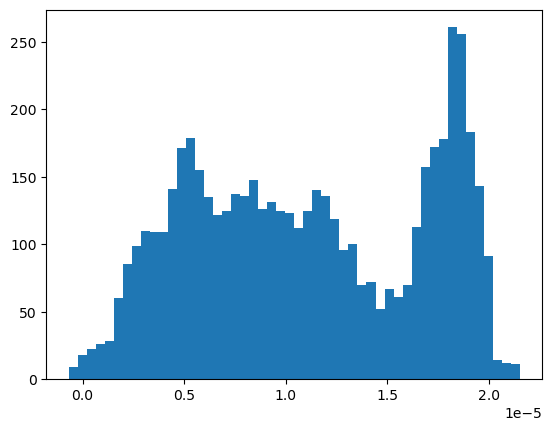

In [ ]:
gaussian = plt.hist(smoothed_image.flatten(), bins=50)
plt.show()

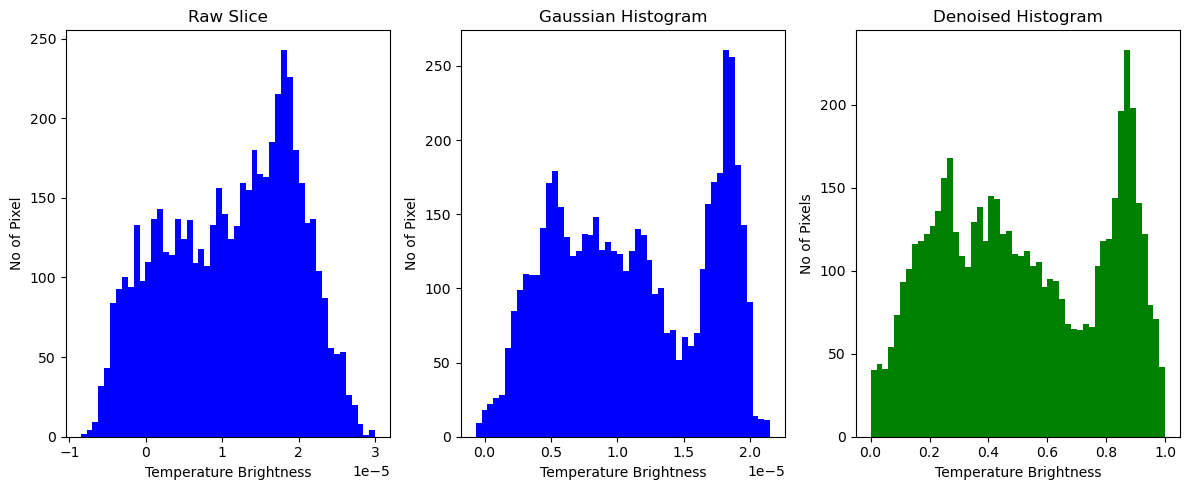

In [ ]:
import matplotlib.pyplot as plt

# Assuming gaussian and denoised are 1D arrays (like flattened image values)
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 5))

axes[0].hist(cosmo_1.flatten(), bins=50, color='blue')
axes[0].set_title('Raw Slice')
axes[0].set_xlabel('Temperature Brightness')
axes[0].set_ylabel('No of Pixel')

# First histogram
axes[1].hist(smoothed_image.flatten(), bins=50, color='blue')
axes[1].set_title('Gaussian Histogram')
axes[1].set_xlabel('Temperature Brightness')
axes[1].set_ylabel('No of Pixel')
# Second histogram
axes[2].hist(denoised_img_norm.flatten(), bins=50, color='green')
axes[2].set_title('Denoised Histogram')
axes[2].set_xlabel("Temperature Brightness")
axes[2].set_ylabel("No of Pixels")

plt.savefig("Comaprison of histograms.png", dpi=600, bbox_inches="tight")

plt.tight_layout()
plt.show()


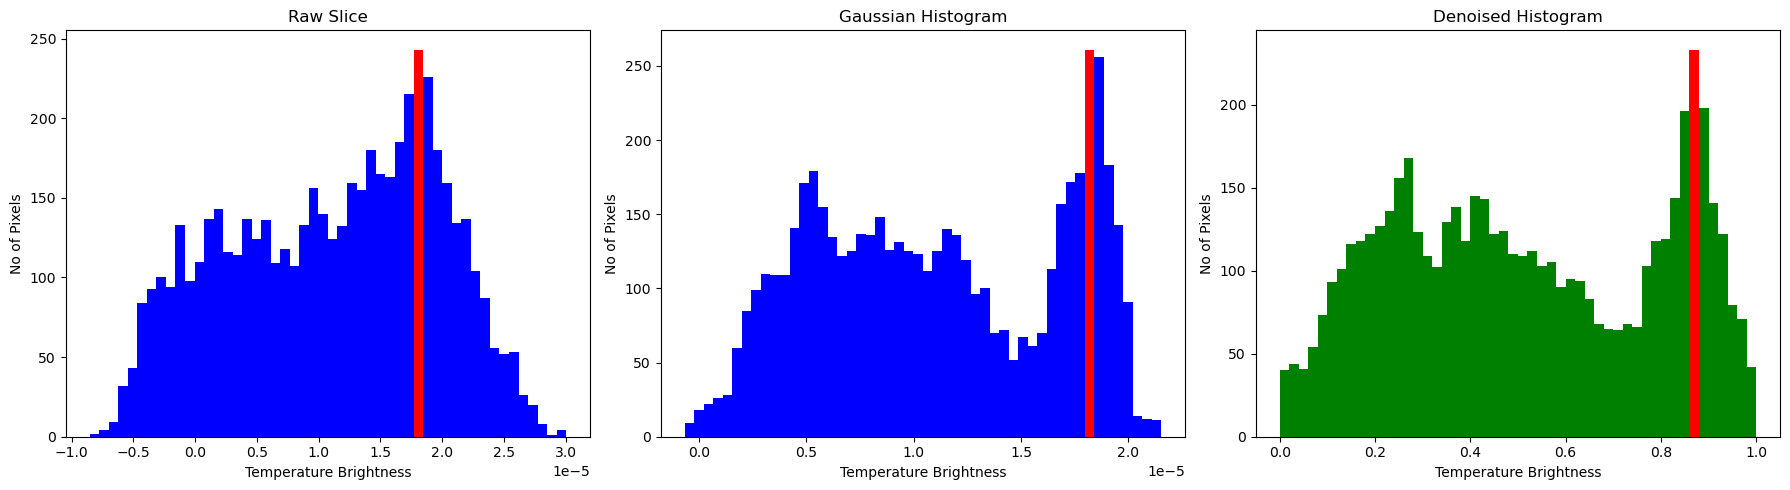

In [ ]:
# List of images and details
images = [cosmo_1, smoothed_image, denoised_img_norm]
titles = ["Raw Slice", "Gaussian Histogram", "Denoised Histogram"]
colors = ['blue', 'blue', 'green']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

for i in range(3):
    data = images[i].flatten()
    counts, bins = np.histogram(data, bins=50)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    peak_idx = np.argmax(counts)

    # Set bar colors: highlight peak
    bar_colors = [colors[i]] * len(counts)
    bar_colors[peak_idx] = 'red'

    # Plot histogram with peak highlighted
    axes[i].bar(bin_centers, counts, width=np.diff(bins), color=bar_colors, align='center')
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Temperature Brightness")
    axes[i].set_ylabel("No of Pixels")

plt.tight_layout()
plt.savefig("Comparison_with_peaks.png", dpi=600, bbox_inches="tight")
plt.show()


In [ ]:
images = [cosmo_1, smoothed_image, denoised_img_normE2]
titles = ["Raw Slice", "Gaussian Histogram", "Denoised Histogram"]
colors = ['blue', 'blue', 'green']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 5))

for i in range(3):
    data = images[i].flatten()
    counts, bins = np.histogram(data, bins=50)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    peak_idx = np.argmax(counts)

    # Get the peak value
    peak_brightness = bin_centers[peak_idx]
    peak_count = counts[peak_idx]

    # Print to console
    print(f"{titles[i]} → Peak Brightness: {peak_brightness:.5e}, Pixel Count: {peak_count}")

    # Bar colors with peak in red
    bar_colors = [colors[i]] * len(counts)
    bar_colors[peak_idx] = 'red'

    # Plot
    axes[i].bar(bin_centers, counts, width=np.diff(bins), color=bar_colors, align='center')
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Temperature Brightness")
    axes[i].set_ylabel("No of Pixels")

    # Annotate on plot
    axes[i].annotate(f'Peak\n{peak_brightness:.2e}',
                     xy=(peak_brightness, peak_count),
                     xytext=(peak_brightness, peak_count + 10),
                     arrowprops=dict(facecolor='red', shrink=0.05),
                     fontsize=8, ha='center')

plt.tight_layout()
plt.savefig("Comparison_with_peak_values.png", dpi=600, bbox_inches="tight")
plt.show()


NameError: name 'denoised_img_normE2' is not defined

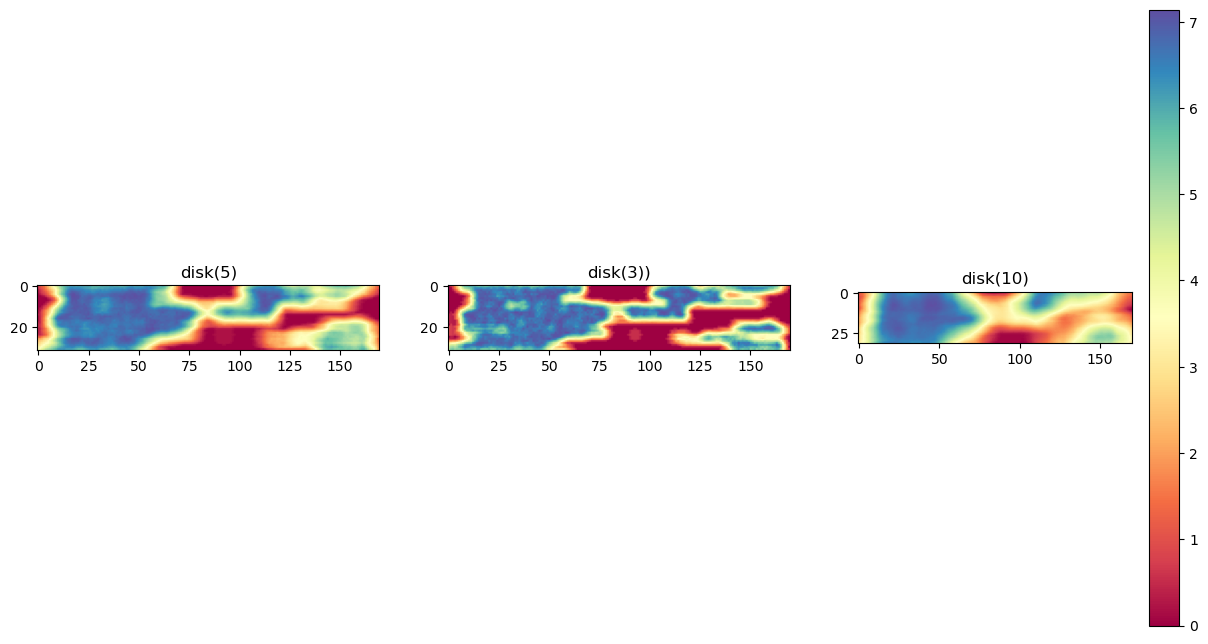

In [ ]:
import numpy as np

from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte

Cosmo_Entropy = img_as_ubyte(exposure.rescale_intensity(cosmo_1))
entropy_map1 = entropy(Cosmo_Entropy, disk(5))
entropy_map2 = entropy(Cosmo_Entropy, disk(3))
entropy_map3 = entropy(Cosmo_Entropy, disk(10))


plt.figure(figsize= (15,8))


plt.subplot(1,3,1); plt.imshow(entropy_map1, cmap='Spectral')
plt.title("disk(5)")
plt.subplot(1,3,2); plt.imshow(entropy_map2, cmap='Spectral')
plt.title("disk(3))")
plt.subplot(1,3,3); plt.imshow(entropy_map3,cmap='Spectral')
plt.title("disk(10)")

plt.colorbar()

plt.show()

In [ ]:
#FFT FOR ENTROPY

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage.util import invert
from skimage.exposure import rescale_intensity

def fft_low_pass_filter(entropy_map3, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(entropy_map3)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(entropy_map3)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))

    return denoised, f_shift, f_filtered

# ---- Step 1: Apply FFT Filter ----
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(entropy_map3, radius=5)

# ---- Step 2: Normalize and Invert ----
denoised_img_normE2 = rescale_intensity(denoised_img, in_range='image', out_range=(0, 1))
inverted_imgE2 = invert(denoised_img_norm)

# ---- Step 3: Plot All Results ----
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(entropy_map3, cmap='gray')
plt.title("Entropy")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fft_original)), cmap='magma')
plt.title("FFT Spectrum (Original)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(denoised_img_normE2, cmap='gray')
plt.title("Denoised (Normalized)")
plt.axis('off')



plt.title("Inverted (Ionized = Dark)")
plt.axis('off')

plt.tight_layout()
plt.show()


NameError: name 'entropy_map3' is not defined

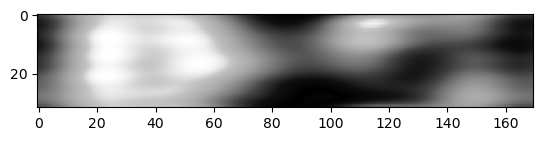

In [ ]:
from skimage import exposure

equalized2 = exposure.equalize_hist(denoised_img_normE2)
plt.imshow(equalized2, cmap='gray')
plt.show()

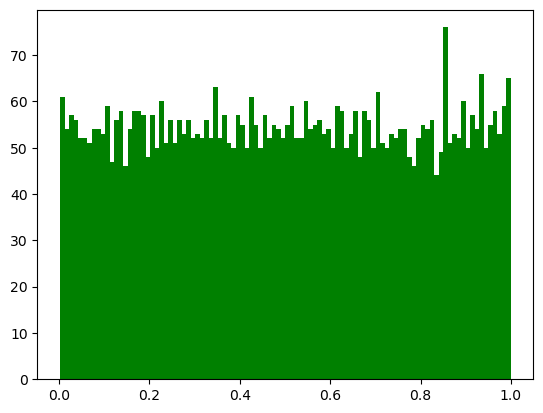

In [ ]:
plt.hist(equalized2.flatten(), bins=100, color='Green')
plt.show()

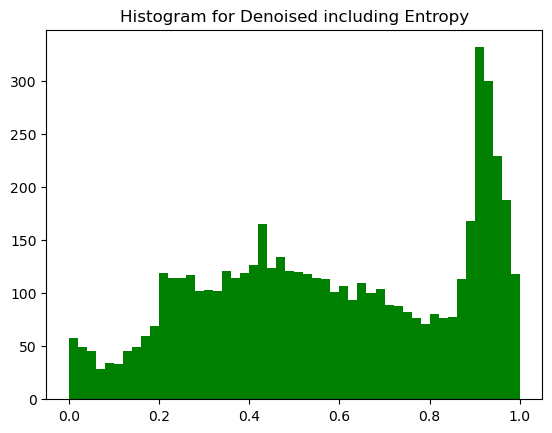

In [ ]:
plt.hist(denoised_img_normE2.flatten(), bins=50, color='Green')
plt.title('Histogram for Denoised including Entropy')
plt.show()

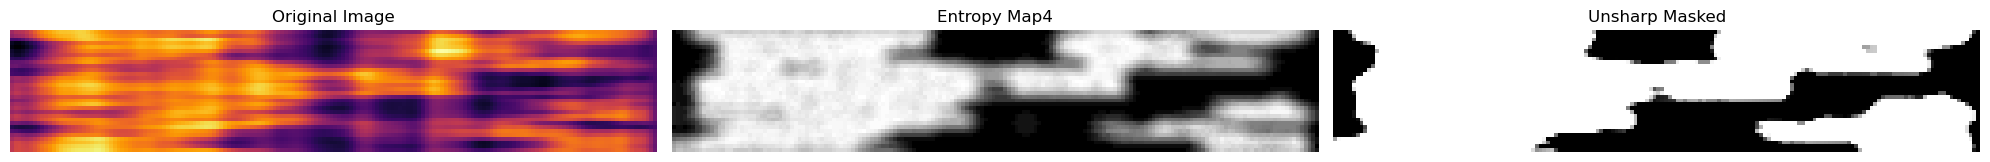

In [ ]:
image = cosmo_1  # Dummy brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(cosmo_1))
entropy_map4 = entropy(entropy_input, morphology.disk(3))

# --- 3. Apply Unsharp Masking to sharpen edges ---
sharpened = unsharp_mask(entropy_map4, radius=20, amount=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(cosmo_1, cmap='inferno')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map4, cmap='gray')
axes[1].set_title("Entropy Map4")
axes[1].axis('off')

axes[2].imshow(sharpened, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

plt.tight_layout()
plt.show()

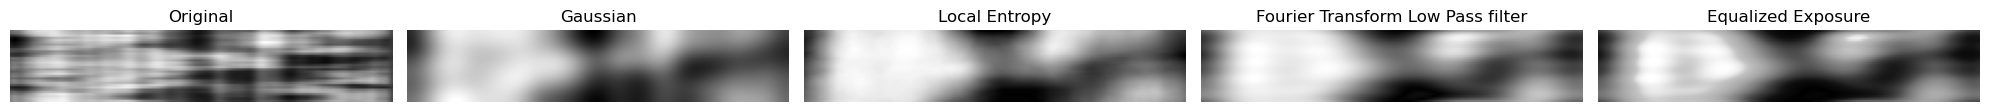

In [ ]:
import matplotlib.pyplot as plt

# Make sure these variables are already defined in your code:
# original_image, smoothed_image, entropy_map3, denoised_img_normE2, equalized2

fig, ax = plt.subplots(1, 5, figsize=(20, 10))  # ✅ 5 axes created

ax[0].imshow(cosmo_1, cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(smoothed_image, cmap='gray')
ax[1].set_title("Gaussian")

ax[2].imshow(entropy_map3, cmap='gray')
ax[2].set_title("Local Entropy")

ax[3].imshow(denoised_img_normE2, cmap='gray')
ax[3].set_title("Fourier Transform Low Pass filter")

ax[4].imshow(equalized2, cmap='gray')
ax[4].set_title("Equalized Exposure")

plt.savefig('Pipleline.png', dpi= 600, bbox_inches="tight")
# Clean up axis ticks
for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()




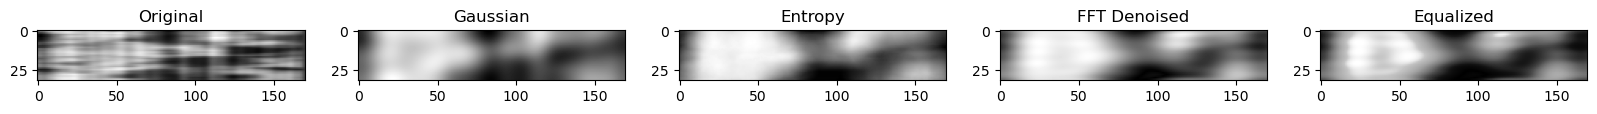

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

# Create subplots
fig, ax = plt.subplots(1, 5, figsize=(20, 5))

# Plot your images
ax[0].imshow(cosmo_1, cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(smoothed_image, cmap='gray')
ax[1].set_title("Gaussian")

ax[2].imshow(entropy_map3, cmap='gray')
ax[2].set_title("Entropy")

ax[3].imshow(denoised_img_normE2, cmap='gray')
ax[3].set_title("FFT Denoised")

ax[4].imshow(equalized2, cmap='gray')
ax[4].set_title("Equalized")
# ✅ Save with clean crop and no axes
plt.savefig('Pipeline_Clean.png', dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()

# Turn off axes
for a in ax:
    a.set_xticks([])  # Remove x-axis ticks
    a.set_yticks([])  # Remove y-axis ticks
    a.set_frame_on(False)  # Remove axis frame
    a.axis('off')  # Turn off axis completely (safe to keep this)

plt.tight_layout()


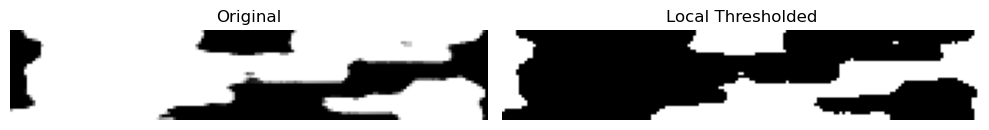

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image3 = sharpened.astype(float)


# Set block size for local thresholding (must be odd)
block_size = 101  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(image3, block_size, offset=offset)


# Apply threshold: pixels > local threshold → foreground (True)
binary_local = image3 < local_thresh

# Plot original and thresholded image
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plt.gray()

ax[0].imshow(sharpened , cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


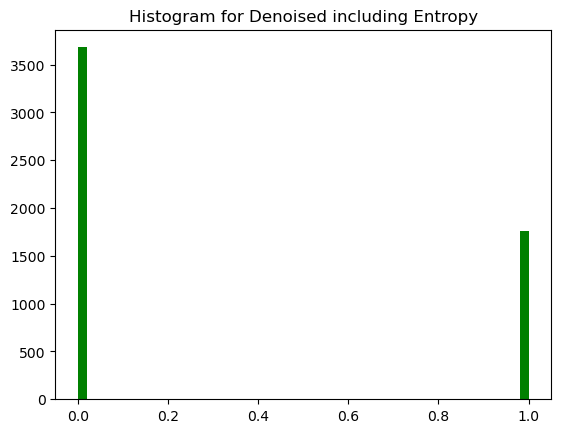

In [ ]:
plt.hist(binary_local.astype(float).flatten(), bins=50, color='Green')
plt.title('Local Threshold')
plt.show()

NameError: name 'cosmo_2' is not defined

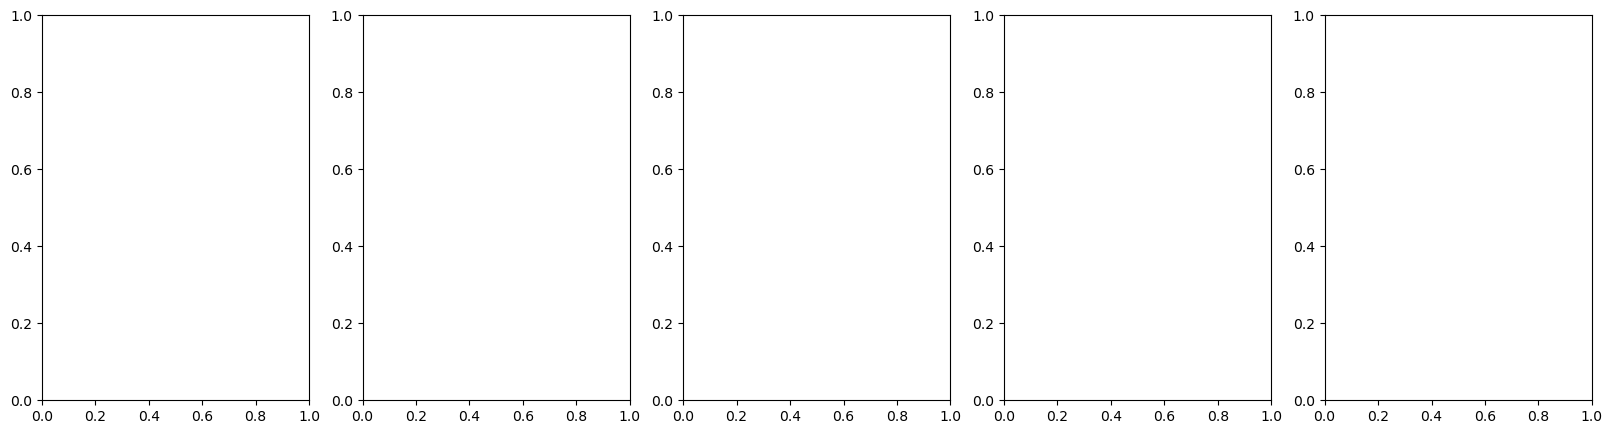

In [ ]:
import matplotlib.pyplot as plt

# Create subplots
fig, ax = plt.subplots(1, 5, figsize=(20, 5))

# Plot your images
ax[0].imshow(cosmo_2, cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(smoothed_image2, cmap='gray')
ax[1].set_title("Gaussian")

ax[2].imshow(entropy_map2, cmap='gray')
ax[2].set_title("Entropy")

ax[3].imshow(denoised_img_norm2, cmap='gray')
ax[3].set_title("FFT Denoised")

ax[4].imshow(equalized2, cmap='gray')
ax[4].set_title("Equalized")
# ✅ Save with clean crop and no axes
plt.savefig('Pipeline_Clean.png', dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()

# Turn off axes
for a in ax:
    a.set_xticks([])  # Remove x-axis ticks
    a.set_yticks([])  # Remove y-axis ticks
    a.set_frame_on(False)  # Remove axis frame
    a.axis('off')  # Turn off axis completely (safe to keep this)

plt.tight_layout()
